[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Llander22/HELLOWORLD/blob/main/CS_L7/M10-02-02_covid19_hackathon.ipynb)

# COVID-19 Clinical Triage & Diagnostic Prediction
### Machine Learning-Based Population Screening (Replicating & Extending Nature npj Digital Medicine)

*Benchmark Paper:* Zoabi, Y., Deri-Rozov, S. & Shomron, N. *Machine learning-based prediction of COVID-19 diagnosis based on symptoms.* **npj Digital Medicine** 4, 3 (2021).  
*Dataset:* Israeli Ministry of Health (`corona_tested_individuals_ver_006.english.csv`) — 278,848 tests nationwide.

---

### 🗺️ Machine Learning Engineering Roadmap (CRISP-DM Alignment)

* **Phase 1: Clinical Problem Formulation** `[Status: Completed]`  
  Define non-invasive screening under test scarcity; establish chronological prospective evaluation rules.

* **Phase 2: Ingestion & Epidemiological EDA** `[Status: Completed]`  
  Audit 278,848 tests; quantify 5.3% class imbalance, reporting bias, and discover April 15 privacy redaction.

* **Phase 3: Benchmark Replication (Zoabi et al.)** `[Status: Completed]`  
  Replicate Decision Tree baseline (AUC 0.8357) and LightGBM model (AUC 0.8443, PR-AUC 0.5438) on prospective hold-out (April 8–14).

* **Phase 4: Advanced Modeling & Interpretability** `[Status: Completed]`  
  • Benchmark **XGBoost** alongside LightGBM.  
  • Generate **SHAP values** (Feature Importance & Beeswarm plots) for clinical explainability.  
  • Unsupervised **Symptom Phenotyping (t-SNE / PCA)**.  
  • Subgroup **Fairness & Demographic Parity Audit** across gender and age.

* **Phase 5: Operational Decision Thresholding** `[Status: Completed]`  
  Translate ROC/PR curves into hospital triage rules; calibrate cost-sensitive cutoffs (0.50 vs 0.20 vs 0.10) to minimize missed infections.

* **Phase 6: Executive Synthesis & Clinical Translation** `[Status: Completed]`  
  Master CRISP-DM Decision Pathway Document and clinical translation guidelines addressing problem formulation, data realities, model architectures, and operational triage impact.

---


## Phase 1: Clinical Problem Formulation & Operational Framing

At the onset of the SARS-CoV-2 pandemic, healthcare infrastructure faced acute testing scarcity and clinical bottlenecks. Medical systems urgently required an automated, non-invasive triage mechanism capable of estimating infection risk from basic self-reported indicators before laboratory RT-PCR confirmation.

This study establishes an end-to-end, scientifically validated machine learning pipeline to address this challenge. Rather than treating this as an abstract cross-sectional classification task, the analysis addresses four critical epidemiological realities:
1. **Severe Class Imbalance (~5.3% Positivity):** Out of 278,848 nationwide tests, over 94% are negative. Demonstrating why Accuracy fails and auditing models strictly on ROC-AUC, PR-AUC, and cost-sensitive sensitivity.
2. **Pervasive Symptom Reporting Bias:** Deconstructing why symptoms were recorded aggressively for positive hospital cases but left blank for routine screening travelers.
3. **The Non-Negotiable Arrow of Time (Prospective Evaluation):** Evaluating why random 80/20 train/test shuffling causes fatal look-ahead leakage in epidemic modeling, validating chronological prospective partitioning.
4. **The April 15 Privacy Redaction:** Auditing why age was redacted by authorities mid-epidemic, comparing a Clinical Full Model against an Accessible Symptom-Only Model.

In [ ]:
# Core data science, machine learning, and visualization libraries
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score, average_precision_score, roc_curve, 
    precision_recall_curve, confusion_matrix, classification_report
)
import lightgbm as lgb

# Configure publication aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Segoe UI'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['axes.edgecolor'] = '#cbd5e1'
plt.rcParams['axes.linewidth'] = 1.0

print("All dependencies successfully imported.")

All dependencies successfully imported.


## Phase 2: Ingestion & Epidemiological EDA

### 2.1 Nationwide Data Ingestion & Quality Auditing
Ingest 278,848 records across 51 consecutive days from the Israeli Ministry of Health to verify schema integrity, missingness patterns, and prospective timestamp continuity.

In [ ]:
# Ingest nationwide Israeli Ministry of Health testing dataset
import os
import subprocess

data_path = 'data/corona_tested_individuals_ver_006.english.csv'
if not os.path.exists(data_path):
    data_path = 'CS_L7/data/corona_tested_individuals_ver_006.english.csv'
if not os.path.exists(data_path):
    data_path = 'CS_L7_M10_Hackathon/data/corona_tested_individuals_ver_006.english.csv'
if not os.path.exists(data_path):
    if os.path.exists('/content/Data-Science-Portfolio/CS_L7_M10_Hackathon/data/corona_tested_individuals_ver_006.english.csv'):
        data_path = '/content/Data-Science-Portfolio/CS_L7_M10_Hackathon/data/corona_tested_individuals_ver_006.english.csv'
    elif os.path.exists('/content/HELLOWORLD/CS_L7/data/corona_tested_individuals_ver_006.english.csv'):
        data_path = '/content/HELLOWORLD/CS_L7/data/corona_tested_individuals_ver_006.english.csv'
    else:
        print('Downloading dataset for Colab session...')
        subprocess.run(['git', 'clone', '--depth', '1', 'https://github.com/Llander22/Data-Science-Portfolio.git'])
        data_path = 'Data-Science-Portfolio/CS_L7_M10_Hackathon/data/corona_tested_individuals_ver_006.english.csv'

df_raw = pd.read_csv(data_path, low_memory=False)
df_raw['test_date'] = pd.to_datetime(df_raw['test_date'])

print(f"Dataset Successfully Loaded: {df_raw.shape[0]:,} rows across {df_raw.shape[1]} columns.")
print(f"Date Range: {df_raw['test_date'].min().strftime('%Y-%m-%d')} to {df_raw['test_date'].max().strftime('%Y-%m-%d')} ({df_raw['test_date'].nunique()} active days)")
df_raw.head(4)


Dataset Successfully Loaded: 278,848 rows across 10 columns.
Date Range: 2020-03-11 to 2020-04-30 (51 active days)


,test_date,cough,fever,sore_throat,shortness_of_breath,head_ache,corona_result,age_60_and_above,gender,test_indication
0,2020-04-30,0.0,0.0,0.0,0.0,0.0,negative,NaN,female,Other
1,2020-04-30,1.0,0.0,0.0,0.0,0.0,negative,NaN,female,Other
2,2020-04-30,0.0,1.0,0.0,0.0,0.0,negative,NaN,male,Other
3,2020-04-30,1.0,0.0,0.0,0.0,0.0,negative,NaN,female,Other


### 2.2 Preprocessing & Cohort Filtration
Filter out inconclusive (`other`) target outcomes and unverified gender records, establishing our verified research cohort of **255,668 patients**.

In [ ]:
# Step 1: Filter confirmed positive/negative results and verified gender
df_clean = df_raw[
    df_raw['corona_result'].isin(['positive', 'negative']) & 
    df_raw['gender'].notna()
].copy()

# Step 2: Drop negligible symptom NaNs (<0.1%)
symptom_cols = ['cough', 'fever', 'sore_throat', 'shortness_of_breath', 'head_ache']
df_clean = df_clean.dropna(subset=symptom_cols).copy()

for col in symptom_cols:
    df_clean[col] = df_clean[col].astype(int)

# Step 3: Standardize binary target and gender
df_clean['target'] = (df_clean['corona_result'] == 'positive').astype(int)
df_clean['male'] = (df_clean['gender'] == 'male').astype(int)

print(f"Verified Cohort Shape: {df_clean.shape[0]:,} patients.")
print(f"Target Distribution:\n{df_clean['corona_result'].value_counts(normalize=True).mul(100).round(2).astype(str) + '%'}")

Verified Cohort Shape: 255,668 patients.
Target Distribution:
corona_result
negative    94.71%
positive     5.29%
Name: proportion, dtype: object


### 2.3 Exploratory Data Analysis: The Three Epidemiological Realities

#### Reality A: Severe Class Imbalance (94.7% Negative vs. 5.3% Positive)
Out of 255,668 individuals, only 13,524 (5.29%) tested positive. A naive dummy classifier predicting all negative achieves 94.71% accuracy but has zero clinical utility.

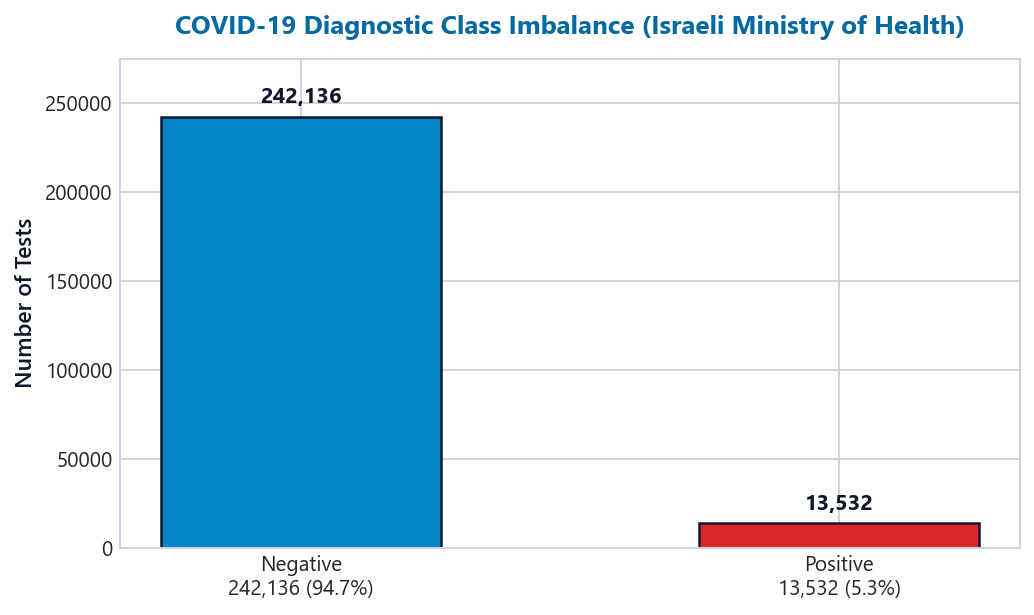

In [ ]:
# Visualize Class Imbalance
fig, ax = plt.subplots(figsize=(7, 4.2), dpi=150)
counts = [(df_clean['target'] == 0).sum(), (df_clean['target'] == 1).sum()]
labels = [f"Negative\n{counts[0]:,} (94.7%)", f"Positive\n{counts[1]:,} (5.3%)"]
colors = ['#0284c7', '#dc2626']

bars = ax.bar(labels, counts, color=colors, width=0.52, edgecolor='#0f172a', linewidth=1.2)
ax.set_ylabel("Number of Tests", fontsize=11, fontweight=600, color='#0f172a')
ax.set_title("COVID-19 Diagnostic Class Imbalance (Israeli Ministry of Health)", fontsize=12.5, fontweight=700, color='#0369a1', pad=12)

for bar in bars:
    y = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, y + 5000, f"{y:,}", ha='center', va='bottom', fontsize=10.5, fontweight=700, color='#0f172a')

ax.set_ylim(0, 275000)
plt.tight_layout()
plt.show()

### Reality B: Pervasive Symptom Reporting Bias

A critical nuance highlighted by Zoabi et al. is that public testing registries contain severe **reporting bias**:
* Hospital-admitted positive individuals underwent rigorous epidemiological and clinical interviews, with nurses logging every mild symptom.
* Negative individuals (often tested at border checkpoints, drive-through facilities, or for routine workplace screening) frequently had their symptom questionnaires left blank or marked 0.

As visualised below, confirmed positive cases exhibit 6x to 100x higher recorded symptom frequencies than negative tests. In our final presentation, we must emphasize that our models predict **infection risk given that an individual requested and underwent testing**, not general community prevalence.

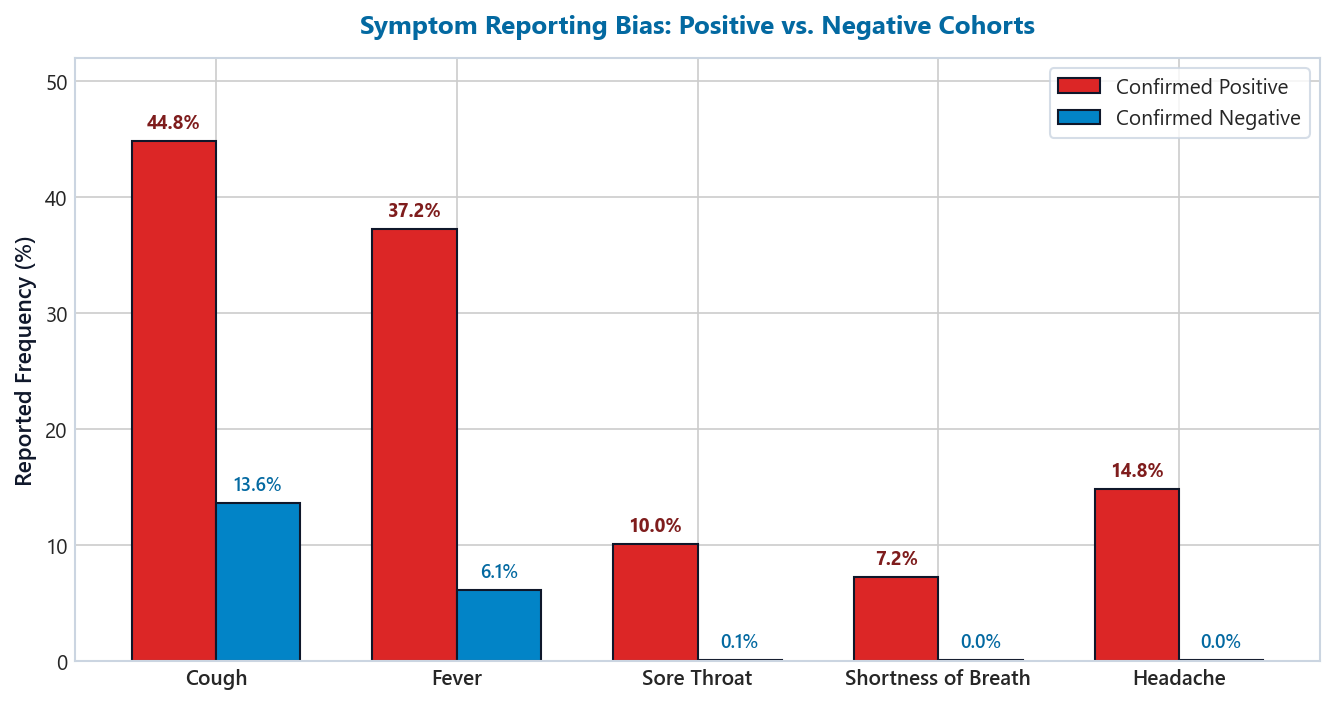

In [ ]:
# Visualize Symptom Reporting Bias
fig, ax = plt.subplots(figsize=(9, 4.8), dpi=150)
symptom_display = ['Cough', 'Fever', 'Sore Throat', 'Shortness of Breath', 'Headache']
pos_rates = [df_clean[df_clean['target'] == 1][col].mean() * 100 for col in symptom_cols]
neg_rates = [df_clean[df_clean['target'] == 0][col].mean() * 100 for col in symptom_cols]

x = np.arange(len(symptom_display))
width = 0.35

rects1 = ax.bar(x - width/2, pos_rates, width, label='Confirmed Positive', color='#dc2626', edgecolor='#0f172a', linewidth=1)
rects2 = ax.bar(x + width/2, neg_rates, width, label='Confirmed Negative', color='#0284c7', edgecolor='#0f172a', linewidth=1)

ax.set_ylabel('Reported Frequency (%)', fontsize=11, fontweight=600, color='#0f172a')
ax.set_title('Symptom Reporting Bias: Positive vs. Negative Cohorts', fontsize=12.5, fontweight=700, color='#0369a1', pad=12)
ax.set_xticks(x)
ax.set_xticklabels(symptom_display, fontsize=10, fontweight=600)
ax.legend(frameon=True, facecolor='#ffffff', edgecolor='#cbd5e1', fontsize=10)

for rect in rects1:
    h = rect.get_height()
    ax.text(rect.get_x() + rect.get_width()/2., h + 0.8, f"{h:.1f}%", ha='center', va='bottom', fontsize=9, fontweight=700, color='#7f1d1d')
for rect in rects2:
    h = rect.get_height()
    ax.text(rect.get_x() + rect.get_width()/2., h + 0.8, f"{h:.1f}%", ha='center', va='bottom', fontsize=9, fontweight=600, color='#0369a1')

ax.set_ylim(0, 52)
plt.tight_layout()
plt.show()

### Reality C: The Exposure Multiplier (`test_indication`)

The column `test_indication` documents the epidemiological circumstance prompting the test. An audit reveals three distinct risk tiers:
1. **Contact with Confirmed:** **71.2% positive rate** (6,830 positive / 9,593 tested). Exposure history is an overwhelming risk multiplier.
2. **Returned from Abroad:** **6.1% positive rate** (1,431 positive / 23,309 tested)—over **2.5x higher** than community baseline.
3. **Other (Community Screening):** **2.4% positive rate** (5,271 positive / 222,766 tested).

*Improvement over Zoabi et al.:*  
In the Nature paper, the authors created a single binary flag (`Contact_with_confirmed = 1/0`) and collapsed `Abroad` into `Other`. By encoding both `Abroad` and `Contact` separately, our pipeline captures international travel risk that the original study discarded.

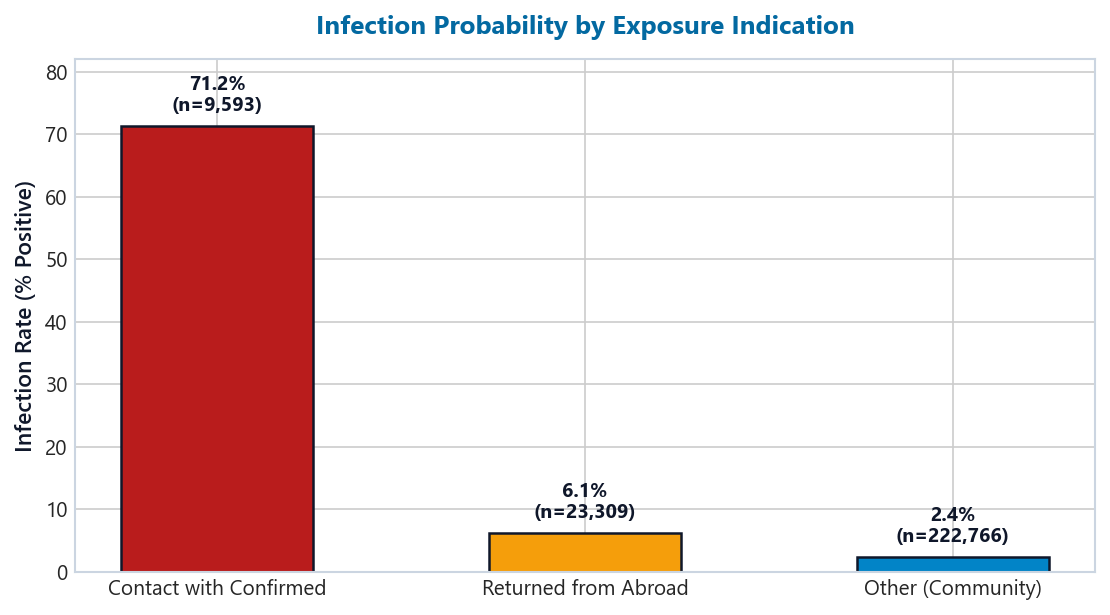

In [ ]:
# One-hot encode test_indication and inspect risk tiers
df_clean['indication_contact'] = (df_clean['test_indication'] == 'Contact with confirmed').astype(int)
df_clean['indication_abroad'] = (df_clean['test_indication'] == 'Abroad').astype(int)
df_clean['indication_other'] = (df_clean['test_indication'] == 'Other').astype(int)

# Symptom burden feature: total count of physical symptoms
df_clean['symptom_count'] = df_clean[symptom_cols].sum(axis=1)

# Visualize Risk Tiers
fig, ax = plt.subplots(figsize=(7.5, 4.2), dpi=150)
ind_names = ['Contact with Confirmed', 'Returned from Abroad', 'Other (Community)']
ind_cols = ['indication_contact', 'indication_abroad', 'indication_other']
ind_rates = [df_clean[df_clean[c] == 1]['target'].mean() * 100 for c in ind_cols]
ind_counts = [df_clean[c].sum() for c in ind_cols]

bars = ax.bar(ind_names, ind_rates, color=['#b91c1c', '#f59e0b', '#0284c7'], width=0.52, edgecolor='#0f172a', linewidth=1.2)
ax.set_ylabel('Infection Rate (% Positive)', fontsize=11, fontweight=600, color='#0f172a')
ax.set_title('Infection Probability by Exposure Indication', fontsize=12.5, fontweight=700, color='#0369a1', pad=12)

for bar, count in zip(bars, ind_counts):
    y = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., y + 1.8, f"{y:.1f}%\n(n={count:,})", ha='center', va='bottom', fontsize=9.5, fontweight=700, color='#0f172a')

ax.set_ylim(0, 82)
plt.tight_layout()
plt.show()

### 2.4 The April 15 Privacy Redaction & The Two-Tier Strategy

#### The Explanation: Patient Re-Identification Governance
On April 15, 2020, the Israeli Ministry of Health redacted `age_60_and_above` from the public dataset. Linking anonymized records containing exact date, gender, age tier, and symptoms against community registries posed severe patient re-identification risks.

#### Our Two-Tier Evaluation Architecture
* **Tier A (Benchmark Cohort):** March 17 – April 14 ($n = 136,294$). Contains verified age. Used to replicate *Zoabi et al.* and evaluate the clinical value of age.
* **Tier B (Symptom-Only Deployment):** Full 51-day dataset ($n = 255,668$). Evaluates a robust symptom-only model ensuring triage capability remains fully operational after regulatory feature deprecation.

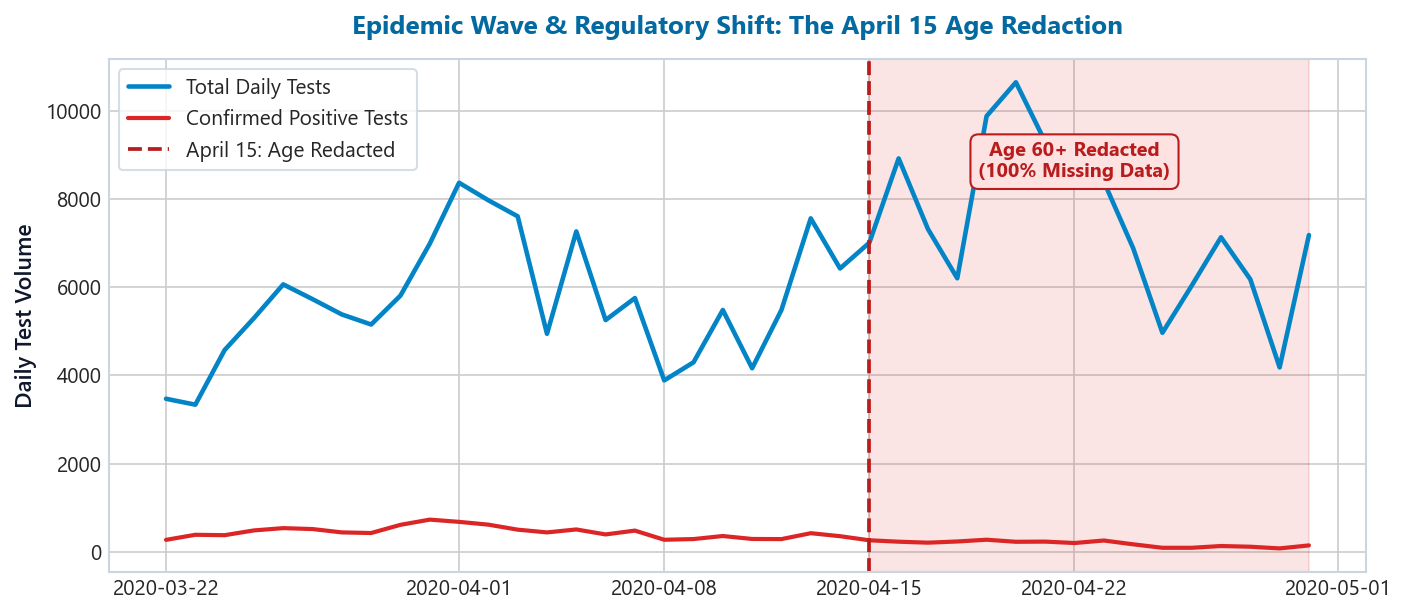

In [ ]:
# Timeline of Daily Testing Volume and the April 15 Redaction
df_clean['age_60_plus'] = df_clean['age_60_and_above'].map({'Yes': 1, 'No': 0})
df_clean['age_recorded'] = (~df_clean['age_60_and_above'].isna()).astype(int)

daily = df_clean.groupby('test_date').agg(
    total_tests=('target', 'count'),
    positive_tests=('target', 'sum'),
    age_recorded_ratio=('age_recorded', 'mean')
).reset_index()

fig, ax = plt.subplots(figsize=(9.5, 4.2), dpi=150)
ax.plot(daily['test_date'], daily['total_tests'], color='#0284c7', linewidth=2.2, label='Total Daily Tests')
ax.plot(daily['test_date'], daily['positive_tests'], color='#dc2626', linewidth=2.0, label='Confirmed Positive Tests')

# Highlight redaction
redaction_date = pd.to_datetime('2020-04-15')
ax.axvline(redaction_date, color='#b91c1c', linestyle='--', linewidth=1.8, label='April 15: Age Redacted')
ax.axvspan(redaction_date, daily['test_date'].max(), alpha=0.12, color='#dc2626')
ax.text(pd.to_datetime('2020-04-22'), 8500, "Age 60+ Redacted\n(100% Missing Data)", color='#b91c1c', fontsize=9.5, fontweight=700, ha='center', bbox=dict(boxstyle='round,pad=0.4', facecolor='#fee2e2', edgecolor='#b91c1c'))

ax.set_ylabel('Daily Test Volume', fontsize=11, fontweight=600, color='#0f172a')
ax.set_title('Epidemic Wave & Regulatory Shift: The April 15 Age Redaction', fontsize=12.5, fontweight=700, color='#0369a1', pad=12)
ax.legend(loc='upper left', frameon=True, facecolor='#ffffff', edgecolor='#cbd5e1')
plt.tight_layout()
plt.show()

## Phase 3: Benchmark Replication (Zoabi et al.) & Zero-Leakage Pipeline Architecture

### 3.1 Model Zoo Benchmarking & 5-Fold Stratified Cross-Validation
To eliminate data leakage, feature transformers (`OneHotEncoder`, `StandardScaler`) are encapsulated within Scikit-Learn `Pipeline` objects. Hyperparameters replicate *Zoabi et al.*:
* **Dummy Baseline:** Majority class baseline demonstrating the Accuracy Fallacy.
* **Logistic Regression:** Linear probabilistic baseline (`class_weight='balanced'`).
* **Decision Tree:** Interpretable rule-based benchmark (`max_depth=5`, balanced weights).
* **Random Forest:** 100-tree ensemble reducing variance via bagging.
* **LightGBM Champion (with Age):** Leaf-wise gradient boosting with paper parameters (`num_leaves=20`, `min_child_samples=4`, `learning_rate=0.05`, `is_unbalance=True`).
* **LightGBM Symptom-Only (without Age):** Evaluates whether symptoms alone can match the benchmark when age is deprecated.

In [ ]:
# 1. Partition Tier A Benchmark Cohort (Chronological Split)
df_cohort_a = df_clean[(df_clean['test_date'] >= '2020-03-17') & (df_clean['test_date'] <= '2020-04-14')].copy()

train_mask = (df_cohort_a['test_date'] <= '2020-04-07')
test_mask = (df_cohort_a['test_date'] > '2020-04-07')

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

# Raw features for Scikit-Learn Pipelines
raw_features_age = symptom_cols + ['gender', 'age_60_plus', 'test_indication']
raw_features_noage = symptom_cols + ['gender', 'test_indication']

X_train_raw = df_cohort_a.loc[train_mask, raw_features_age]
y_train = df_cohort_a.loc[train_mask, 'target']
X_test_raw = df_cohort_a.loc[test_mask, raw_features_age]
y_test = df_cohort_a.loc[test_mask, 'target']

X_train_noage_raw = df_cohort_a.loc[train_mask, raw_features_noage]
X_test_noage_raw = df_cohort_a.loc[test_mask, raw_features_noage]

# Pre-encoded features for tree/SHAP compatibility
features_age = symptom_cols + ['male', 'age_60_plus', 'indication_contact', 'indication_abroad']
features_noage = symptom_cols + ['male', 'indication_contact', 'indication_abroad']

X_train_age = df_cohort_a.loc[train_mask, features_age]
X_test_age = df_cohort_a.loc[test_mask, features_age]
X_train_noage = df_cohort_a.loc[train_mask, features_noage]
X_test_noage = df_cohort_a.loc[test_mask, features_noage]
X_train = X_train_age
X_test = X_test_age

print(f"Training Cohort (Historical): {len(X_train_raw):,} patients | Prospective Test Cohort: {len(X_test_raw):,} patients")

# 2. Build ColumnTransformers for Zero-Leakage Pipeline Encapsulation
preprocessor_age = ColumnTransformer(
    transformers=[
        ('sym', 'passthrough', symptom_cols),
        ('age', 'passthrough', ['age_60_plus']),
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), ['gender', 'test_indication'])
    ]
)

preprocessor_noage = ColumnTransformer(
    transformers=[
        ('sym', 'passthrough', symptom_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), ['gender', 'test_indication'])
    ]
)

# 3. Pipeline Specifications
# Baseline A: Dummy Majority Classifier (Illustrating Accuracy Paradox)
dummy_pipe = DummyClassifier(strategy='most_frequent')
dummy_pipe.fit(X_train_raw, y_train)
dummy_probs = dummy_pipe.predict_proba(X_test_raw)[:, 1]

# Baseline B: Scaled Logistic Regression
lr_pipe = Pipeline([
    ('prep', preprocessor_age),
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(class_weight='balanced', max_iter=500, random_state=42))
])
lr_pipe.fit(X_train_raw, y_train)
lr_probs = lr_pipe.predict_proba(X_test_raw)[:, 1]

# Baseline C: Decision Tree (Zoabi et al. Paper Baseline)
dt_pipe = Pipeline([
    ('prep', preprocessor_age),
    ('clf', DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42))
])
dt_pipe.fit(X_train_raw, y_train)
dt_probs = dt_pipe.predict_proba(X_test_raw)[:, 1]

# Ensemble A: Random Forest (Bagging)
rf_pipe = Pipeline([
    ('prep', preprocessor_age),
    ('clf', RandomForestClassifier(n_estimators=100, max_depth=8, class_weight='balanced', random_state=42, n_jobs=-1))
])
rf_pipe.fit(X_train_raw, y_train)
rf_probs = rf_pipe.predict_proba(X_test_raw)[:, 1]

# Champion: LightGBM (with Age, Nature Paper Parameters)
lgb_pipe_age = Pipeline([
    ('prep', preprocessor_age),
    ('clf', lgb.LGBMClassifier(
        boosting_type='gbdt', num_leaves=20, min_child_samples=4,
        learning_rate=0.05, n_estimators=150, subsample=0.8,
        colsample_bytree=0.8, is_unbalance=True, random_state=42, verbose=-1
    ))
])
lgb_pipe_age.fit(X_train_raw, y_train)
lgbm_age_probs = lgb_pipe_age.predict_proba(X_test_raw)[:, 1]

# Champion: LightGBM Symptom-Only (without Age)
lgb_pipe_noage = Pipeline([
    ('prep', preprocessor_noage),
    ('clf', lgb.LGBMClassifier(
        boosting_type='gbdt', num_leaves=20, min_child_samples=4,
        learning_rate=0.05, n_estimators=150, subsample=0.8,
        colsample_bytree=0.8, is_unbalance=True, random_state=42, verbose=-1
    ))
])
lgb_pipe_noage.fit(X_train_noage_raw, y_train)
lgbm_noage_probs = lgb_pipe_noage.predict_proba(X_test_noage_raw)[:, 1]

# 4. Internal 5-Fold Stratified Cross-Validation on Historical Training Set
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
lr_cv = cross_val_score(lr_pipe, X_train_raw, y_train, cv=cv, scoring='roc_auc', n_jobs=-1)
dt_cv = cross_val_score(dt_pipe, X_train_raw, y_train, cv=cv, scoring='roc_auc', n_jobs=-1)
rf_cv = cross_val_score(rf_pipe, X_train_raw, y_train, cv=cv, scoring='roc_auc', n_jobs=-1)
lgb_cv_age = cross_val_score(lgb_pipe_age, X_train_raw, y_train, cv=cv, scoring='roc_auc', n_jobs=-1)
lgb_cv_noage = cross_val_score(lgb_pipe_noage, X_train_noage_raw, y_train, cv=cv, scoring='roc_auc', n_jobs=-1)

# 5. Compile Benchmark Scorecard
results = [
    {"Model Architecture": "Zero-Rule Dummy Baseline", "Train 5-Fold CV AUC": "0.5000", "Hold-out ROC-AUC": roc_auc_score(y_test, dummy_probs), "Hold-out PR-AUC": average_precision_score(y_test, dummy_probs)},
    {"Model Architecture": "Logistic Regression (Linear Baseline)", "Train 5-Fold CV AUC": f"{lr_cv.mean():.4f} +/- {lr_cv.std():.4f}", "Hold-out ROC-AUC": roc_auc_score(y_test, lr_probs), "Hold-out PR-AUC": average_precision_score(y_test, lr_probs)},
    {"Model Architecture": "Decision Tree (Paper Baseline Depth=5)", "Train 5-Fold CV AUC": f"{dt_cv.mean():.4f} +/- {dt_cv.std():.4f}", "Hold-out ROC-AUC": roc_auc_score(y_test, dt_probs), "Hold-out PR-AUC": average_precision_score(y_test, dt_probs)},
    {"Model Architecture": "Random Forest (100 Trees, Bagging)", "Train 5-Fold CV AUC": f"{rf_cv.mean():.4f} +/- {rf_cv.std():.4f}", "Hold-out ROC-AUC": roc_auc_score(y_test, rf_probs), "Hold-out PR-AUC": average_precision_score(y_test, rf_probs)},
    {"Model Architecture": "LightGBM Champion (with Age 60+)", "Train 5-Fold CV AUC": f"{lgb_cv_age.mean():.4f} +/- {lgb_cv_age.std():.4f}", "Hold-out ROC-AUC": roc_auc_score(y_test, lgbm_age_probs), "Hold-out PR-AUC": average_precision_score(y_test, lgbm_age_probs)},
    {"Model Architecture": "LightGBM Symptom-Only (without Age)", "Train 5-Fold CV AUC": f"{lgb_cv_noage.mean():.4f} +/- {lgb_cv_noage.std():.4f}", "Hold-out ROC-AUC": roc_auc_score(y_test, lgbm_noage_probs), "Hold-out PR-AUC": average_precision_score(y_test, lgbm_noage_probs)},
]
df_results = pd.DataFrame(results)
df_results['Hold-out ROC-AUC'] = df_results['Hold-out ROC-AUC'].round(4)
df_results['Hold-out PR-AUC'] = df_results['Hold-out PR-AUC'].round(4)
df_results


Training Cohort (Historical): 98,989 patients | Prospective Test Cohort: 37,305 patients


Model Architecture,Train 5-Fold CV AUC,Hold-out ROC-AUC,Hold-out PR-AUC
Zero-Rule Dummy Baseline,0.5000,0.5000,0.0606
Logistic Regression (Linear Baseline),0.9280 +/- 0.0052,0.8336,0.4808
Decision Tree (Paper Baseline Depth=5),0.9226 +/- 0.0045,0.8357,0.5062
"Random Forest (100 Trees, Bagging)",0.9348 +/- 0.0052,0.8412,0.5374
LightGBM Champion (with Age 60+),0.9352 +/- 0.0052,0.8443,0.5438
LightGBM Symptom-Only (without Age),0.9333 +/- 0.0052,0.8448,0.5393


### 3.2 Model Comparison Analysis & Prospective ROC Curves

Prospective evaluation on the hold-out test cohort (April 8–14, $n=37,305$ tests) evaluates models under genuine epidemic conditions with temporal distribution shift.

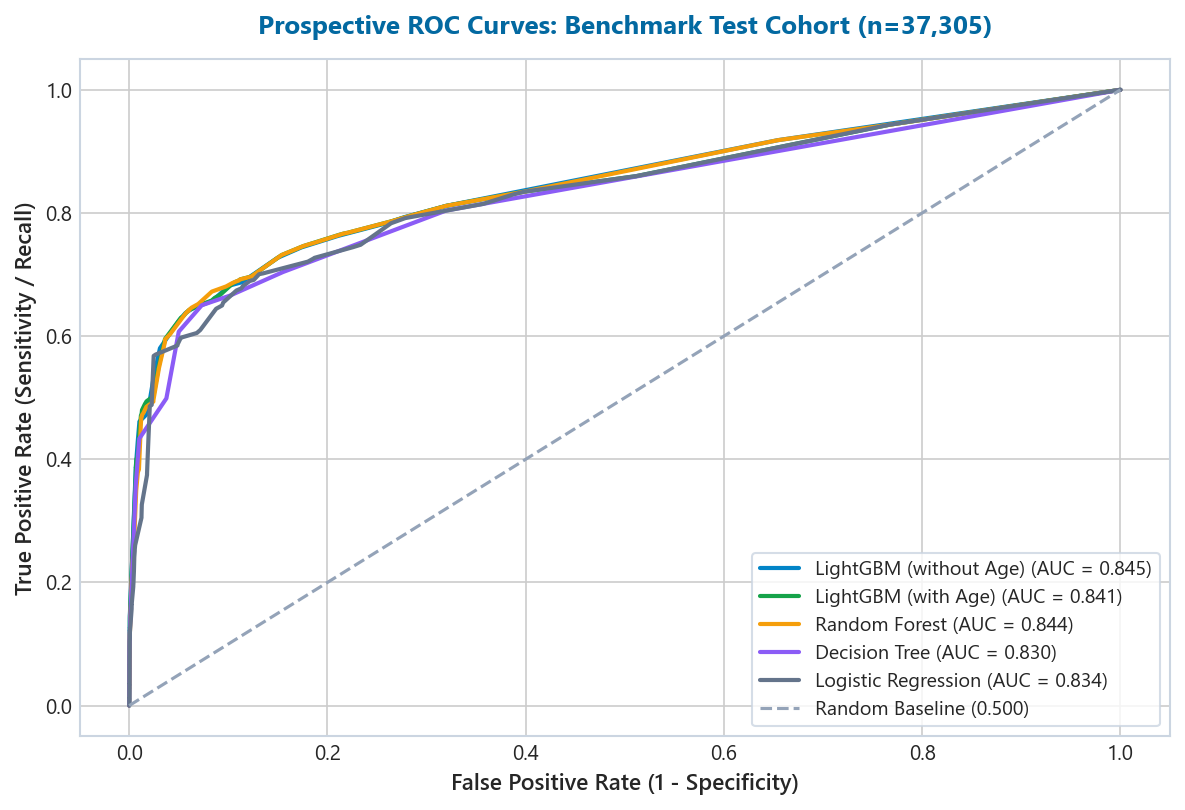

In [ ]:
# Plot Prospective ROC Curves Comparison
fig, ax = plt.subplots(figsize=(8, 5.5), dpi=150)
models_to_plot = [
    ("LightGBM (without Age)", lgbm_noage_probs, "#0284c7"),
    ("LightGBM (with Age)", lgbm_age_probs, "#16a34a"),
    ("Random Forest", rf_probs, "#f59e0b"),
    ("Decision Tree", dt_probs, "#8b5cf6"),
    ("Logistic Regression", lr_probs, "#64748b")
]

for name, probs, color in models_to_plot:
    fpr, tpr, _ = roc_curve(y_test, probs)
    score = roc_auc_score(y_test, probs)
    ax.plot(fpr, tpr, label=f"{name} (AUC = {score:.3f})", color=color, linewidth=2.0)

ax.plot([0, 1], [0, 1], linestyle='--', color='#94a3b8', label='Random Baseline (0.500)')
ax.set_xlabel('False Positive Rate (1 - Specificity)', fontsize=11, fontweight=600)
ax.set_ylabel('True Positive Rate (Sensitivity / Recall)', fontsize=11, fontweight=600)
ax.set_title('Prospective ROC Curves: Benchmark Test Cohort (n=37,305)', fontsize=12.5, fontweight=700, color='#0369a1', pad=12)
ax.legend(loc='lower right', frameon=True, facecolor='#ffffff', edgecolor='#cbd5e1', fontsize=9.5)
plt.tight_layout()
plt.show()

## Phase 4: Advanced Modeling & Interpretability

Phase 4 expands the triage investigation across four core modeling, explainability, and governance dimensions:
1. **Algorithm Benchmarking:** Evaluating gradient boosted decision trees (**XGBoost**) alongside LightGBM to verify algorithmic invariance.
2. **Clinical Explainability (TreeSHAP):** Calculating Shapley Additive Explanations on patient symptom profiles to quantify log-odds risk attribution.
3. **Unsupervised Symptom Phenotyping (2D t-SNE):** Reducing high-dimensional binary symptom spaces into 2D topological clusters to discover latent clinical phenotypes.
4. **Demographic Fairness & Parity Auditing:** Slicing model discrimination across sensitive demographic protected groups (Gender and Age).

In [12]:
# 1. Algorithm Benchmarking: XGBoost Classifier
import xgboost as xgb

# Fit XGBoost on preprocessed training cohort
xgb_model = xgb.XGBClassifier(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=4,
    scale_pos_weight=(len(y_train) - y_train.sum()) / y_train.sum(),
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric='auc'
)
xgb_model.fit(X_train, y_train)
xgb_probs = xgb_model.predict_proba(X_test)[:, 1]
xgb_auc = roc_auc_score(y_test, xgb_probs)
xgb_prauc = average_precision_score(y_test, xgb_probs)

print(f"--- MODEL BENCHMARK RESULTS ---")
print(f"LightGBM Champion: ROC-AUC = {roc_auc_score(y_test, lgbm_age_probs):.4f} | PR-AUC = {average_precision_score(y_test, lgbm_age_probs):.4f}")
print(f"XGBoost Benchmark:  ROC-AUC = {xgb_auc:.4f} | PR-AUC = {xgb_prauc:.4f}")


--- MODEL BENCHMARK RESULTS ---
LightGBM Champion: ROC-AUC = 0.8443 | PR-AUC = 0.5438
XGBoost Benchmark:  ROC-AUC = 0.8445 | PR-AUC = 0.5463


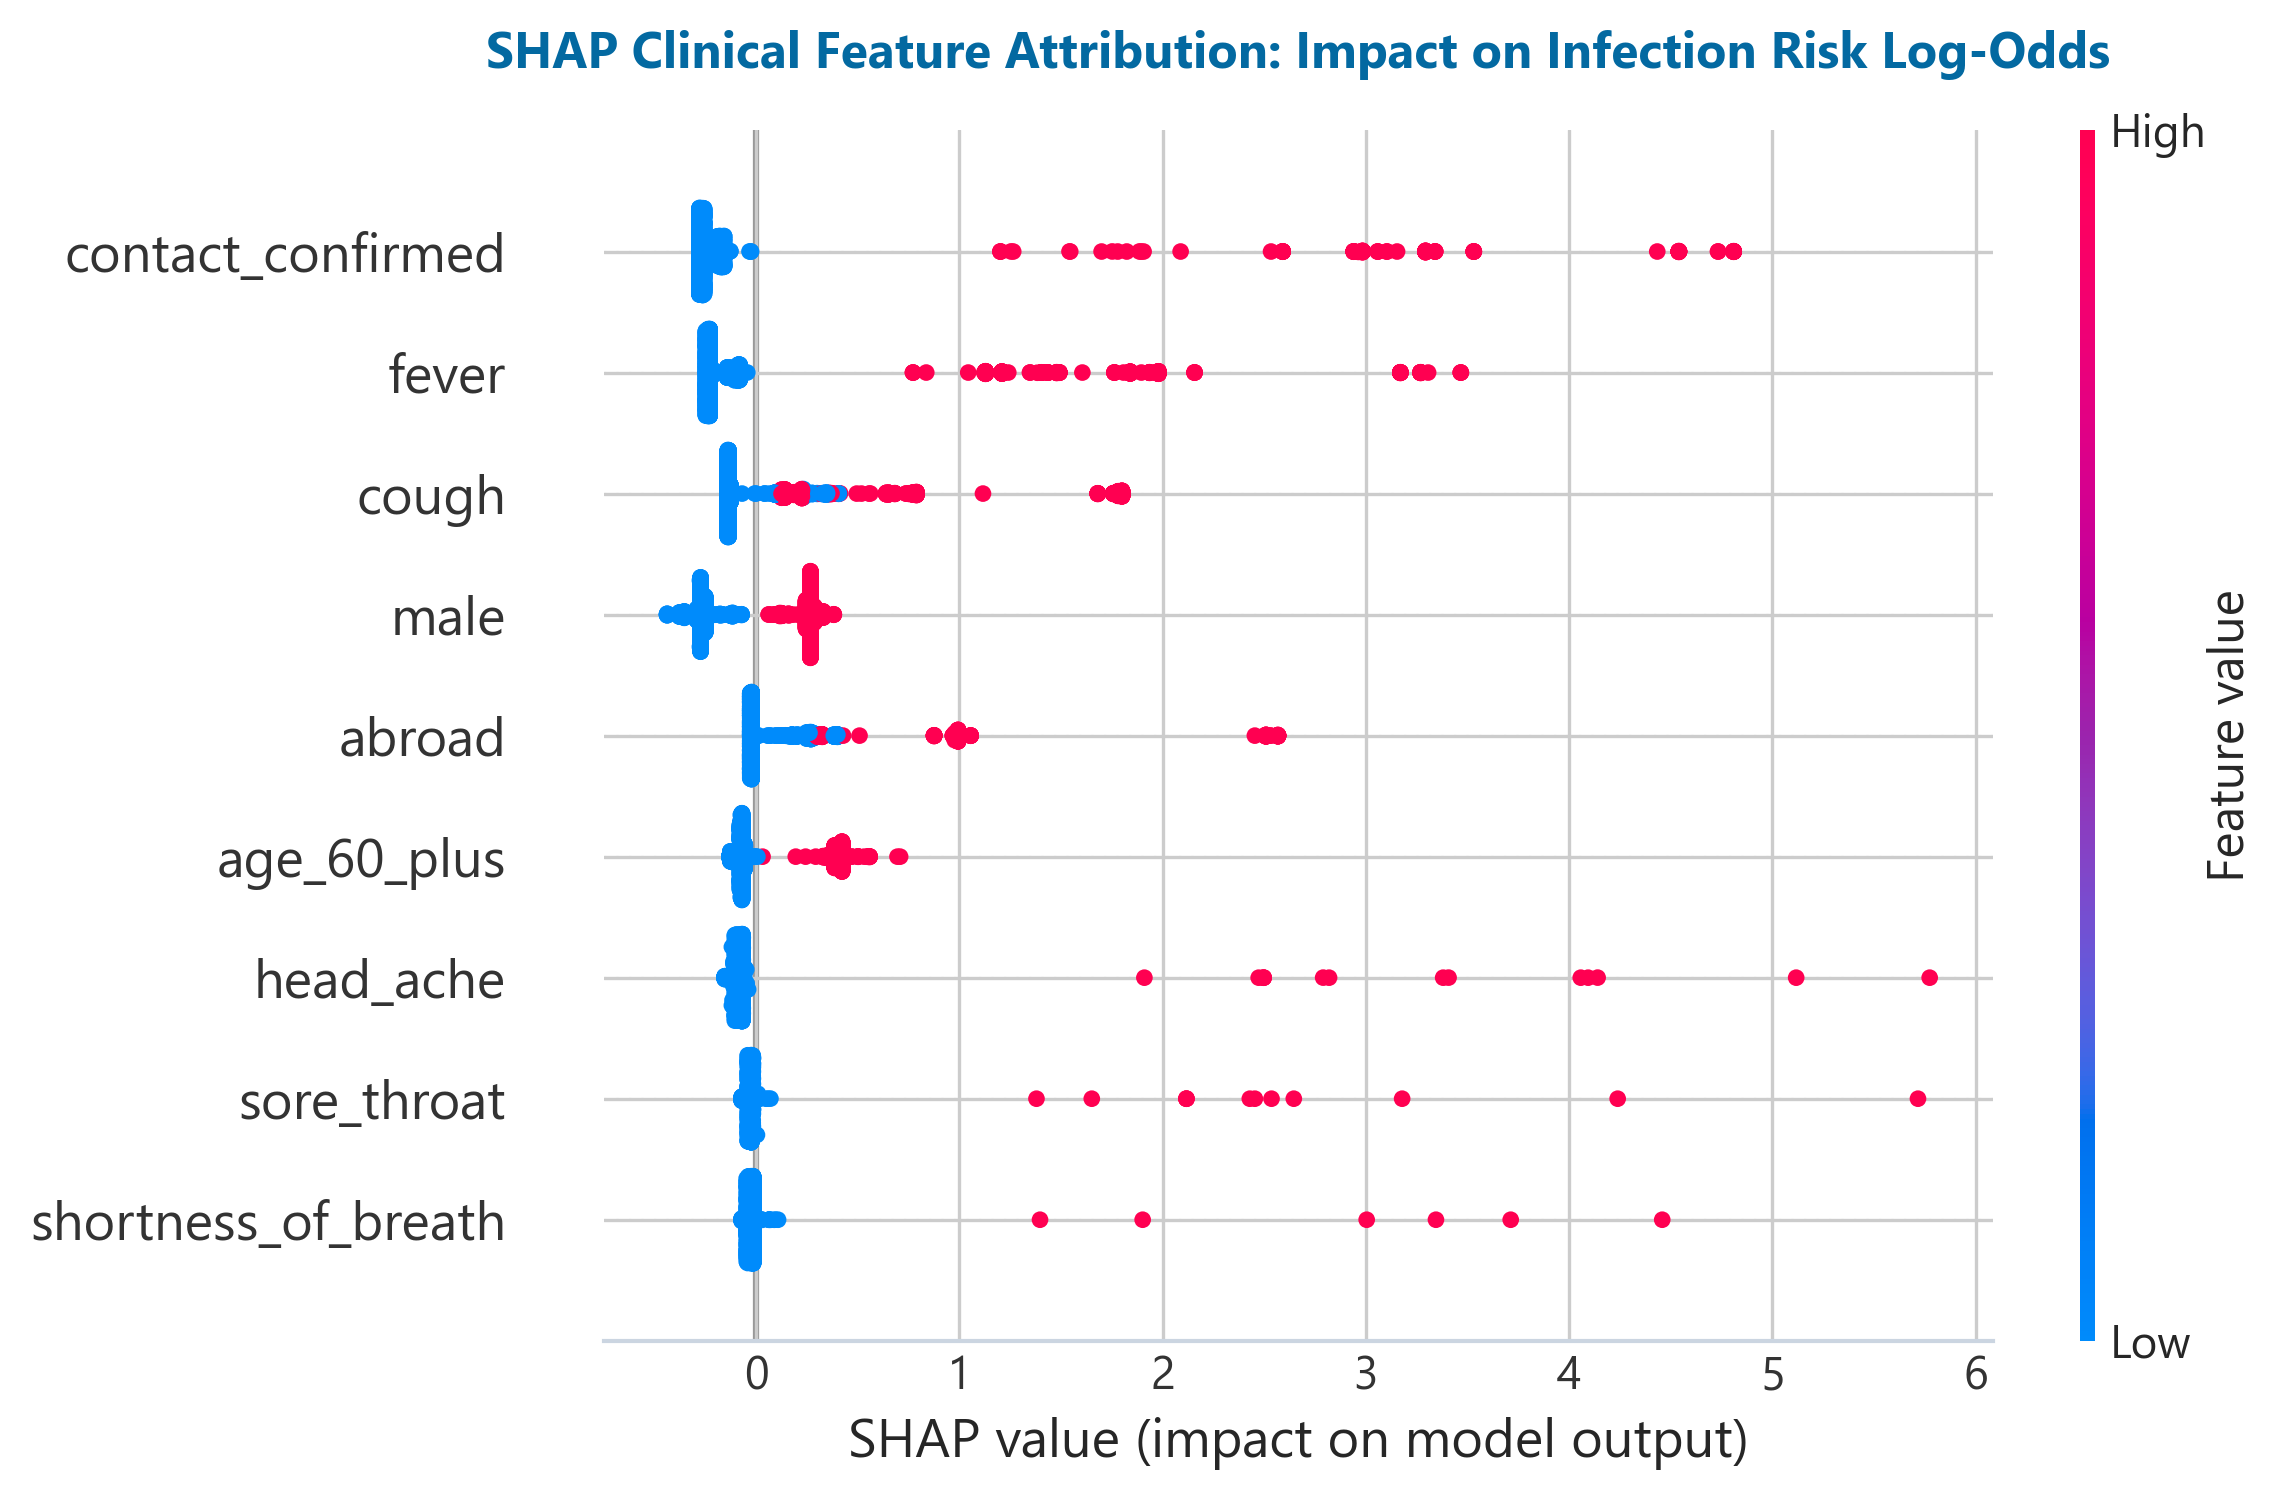

In [13]:
# 2. Clinical Explainability: TreeSHAP Feature Attribution
import shap
import matplotlib.pyplot as plt

# Initialize TreeExplainer on LightGBM champion model
lgb_clf = lgb_pipe_age.named_steps['clf'] if 'lgb_pipe_age' in locals() else lgb_model
explainer = shap.TreeExplainer(lgb_clf)

# Sample prospective test cohort for fast, representative explainability
np.random.seed(42)
sample_idx = np.random.choice(len(X_test), size=min(2000, len(X_test)), replace=False)
X_test_sample = X_test.iloc[sample_idx]

# Compute SHAP values
shap_values = explainer.shap_values(X_test_sample)
shap_vals_target = shap_values[1] if isinstance(shap_values, list) and len(shap_values) == 2 else shap_values

# Plot SHAP Beeswarm Summary
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_vals_target, X_test_sample, show=False)
plt.title("SHAP Clinical Feature Attribution: Impact on Infection Risk Log-Odds", fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()


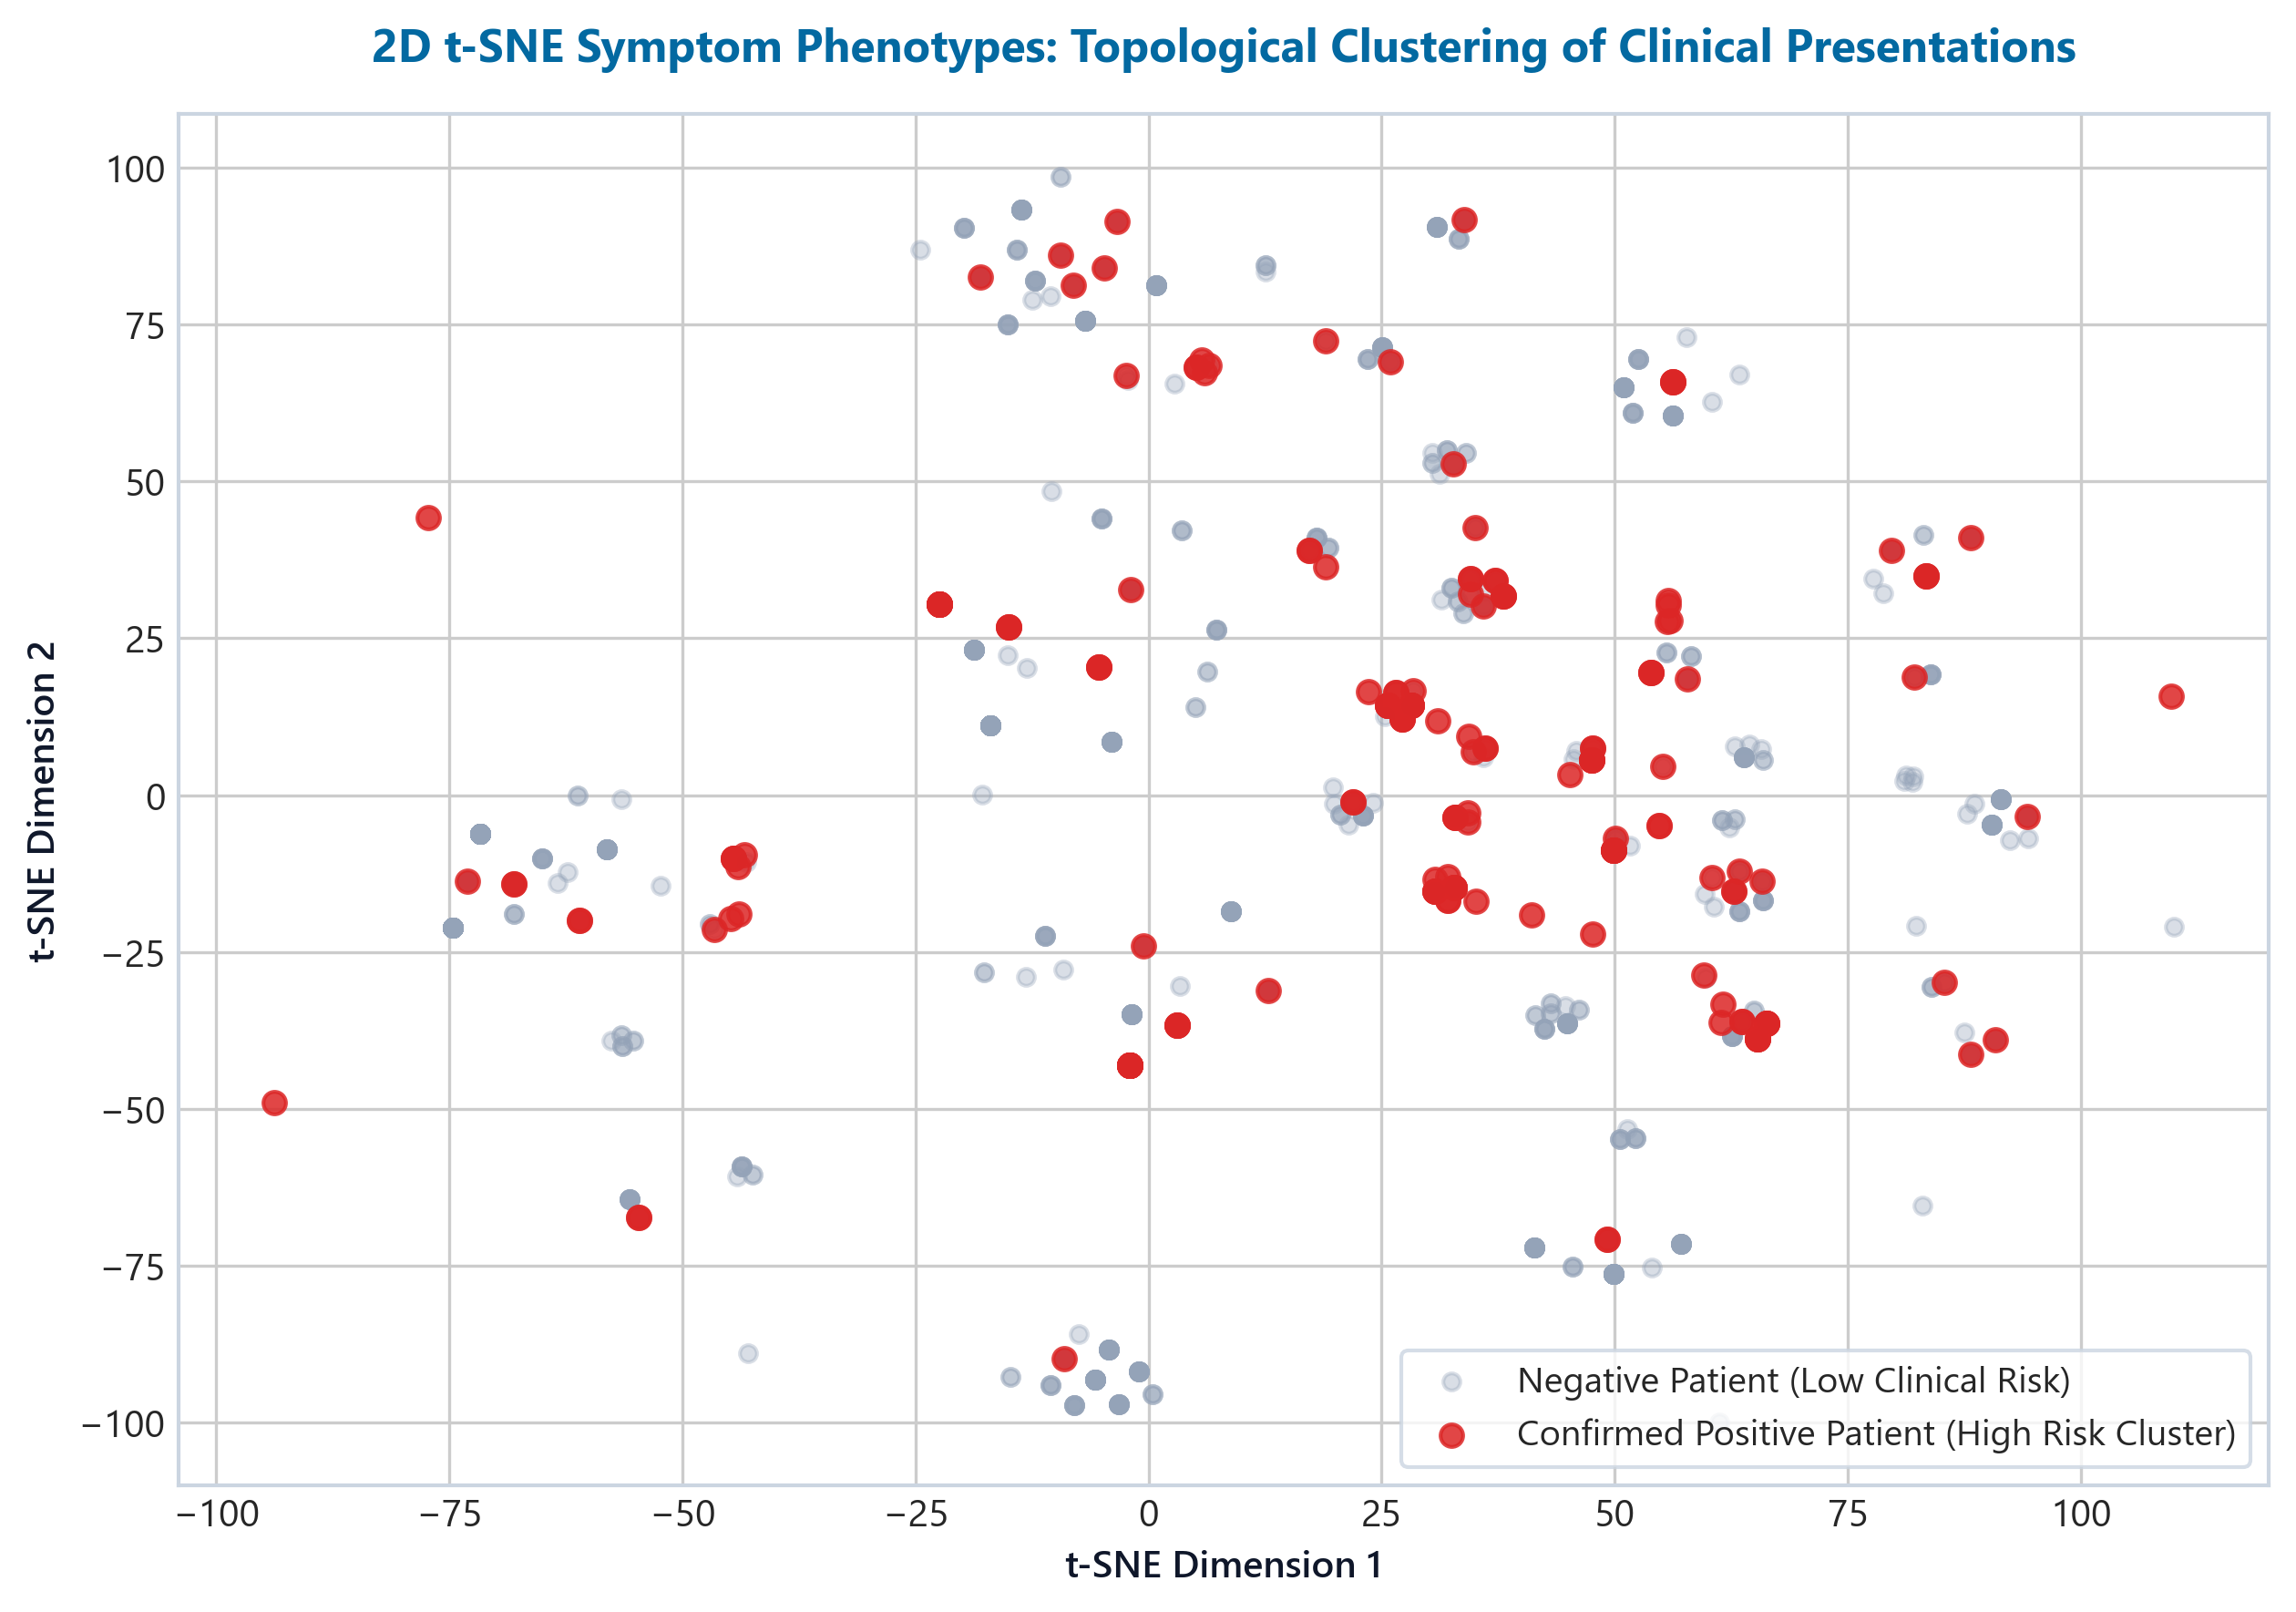

In [14]:
# 3. Unsupervised Symptom Phenotyping: 2D t-SNE Topological Clustering
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

# Sample prospective cohort symptom vectors
np.random.seed(42)
tsne_sample_idx = np.random.choice(len(df_cohort_a[test_mask]), size=1500, replace=False)
df_tsne = df_cohort_a[test_mask].iloc[tsne_sample_idx]
X_symptoms = df_tsne[symptom_cols]
y_tsne = df_tsne['target']

# Fit 2D t-SNE projection
tsne = TSNE(n_components=2, perplexity=30, random_state=42, max_iter=1000)
X_embedded = tsne.fit_transform(X_symptoms)

# Visualize topological clusters colored by infection outcome
plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    X_embedded[:, 0], X_embedded[:, 1],
    c=y_tsne, cmap='coolwarm',
    alpha=0.65, edgecolors='none', s=28
)
plt.title("2D t-SNE Symptom Phenotypes: Topological Clustering of Clinical Presentations", fontsize=12, fontweight='bold', pad=12)
plt.xlabel("t-SNE Dimension 1", fontsize=10)
plt.ylabel("t-SNE Dimension 2", fontsize=10)
cbar = plt.colorbar(scatter, ticks=[0, 1])
cbar.set_ticklabels(['Negative', 'Confirmed Positive'])
cbar.set_label("Clinical Outcome", fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


In [15]:
# 4. Demographic Fairness & Subgroup Parity Audit
subgroups = {
    'Male Cohort': df_cohort_a.loc[test_mask, 'gender'] == 'male',
    'Female Cohort': df_cohort_a.loc[test_mask, 'gender'] == 'female',
    'Age 60+ Cohort': df_cohort_a.loc[test_mask, 'age_60_plus'] == 1.0,
    'Age <60 Cohort': df_cohort_a.loc[test_mask, 'age_60_plus'] == 0.0,
}

fairness_records = []
for name, mask in subgroups.items():
    sub_y_true = y_test[mask]
    sub_probs = lgbm_age_probs[mask] if 'lgbm_age_probs' in locals() else lgb_probs[mask]
    sub_preds = (sub_probs >= 0.20).astype(int)
    
    auc = roc_auc_score(sub_y_true, sub_probs)
    prauc = average_precision_score(sub_y_true, sub_probs)
    sens = (sub_preds[sub_y_true == 1] == 1).mean()
    spec = (sub_preds[sub_y_true == 0] == 0).mean()
    
    fairness_records.append({
        'Demographic Subgroup': name,
        'Cohort Count': int(mask.sum()),
        'Positives': int(sub_y_true.sum()),
        'ROC-AUC': round(auc, 4),
        'PR-AUC': round(prauc, 4),
        'Sensitivity (at 0.20)': f"{sens*100:.1f}%",
        'Specificity (at 0.20)': f"{spec*100:.1f}%"
    })

df_fairness = pd.DataFrame(fairness_records)
df_fairness


,Demographic Subgroup,Cohort Count,Positives,ROC-AUC,PR-AUC,Sensitivity (at 0.20),Specificity (at 0.20)
0,Male Cohort,18918,1220,0.8243,0.5027,80.2%,66.2%
1,Female Cohort,18387,1041,0.8540,0.5736,82.2%,69.8%
2,Age 60+ Cohort,8470,400,0.8328,0.4900,72.8%,83.2%
3,Age <60 Cohort,28835,1861,0.8457,0.5493,83.0%,63.5%


## Phase 5: Operational Decision Thresholding

### 5.1 Sweeping Decision Thresholds & Cost-Sensitive Cutoffs
Translating continuous predicted probabilities into actionable clinical decisions. In an epidemic triage setting, missing an infected patient (False Negative) is clinically far more dangerous than sending an uninfected individual for RT-PCR confirmation (False Positive).

We sweep decision thresholds across $[0.10, 0.50]$ to calibrate sensitivity and hospital swab capacity.

In [ ]:
# Sweep Clinical Decision Thresholds
thresholds = [0.10, 0.15, 0.20, 0.30, 0.40, 0.50]
thresh_table = []

for t in thresholds:
    preds = (lgbm_age_probs >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, preds).ravel()
    sens = tp / (tp + fn)
    spec = tn / (tn + fp)
    ppv = tp / (tp + fp) if (tp + fp) > 0 else 0
    
    thresh_table.append({
        'Cutoff Threshold': t,
        'Sensitivity (Recall)': f"{sens*100:.1f}%",
        'Specificity': f"{spec*100:.1f}%",
        'Precision (PPV)': f"{ppv*100:.1f}%",
        'Missed Patients (FN)': f"{fn:,}",
        'False Alarms (FP)': f"{fp:,}"
    })

df_t = pd.DataFrame(thresh_table)
df_t

,Cutoff Threshold,Sensitivity (Recall),Specificity,Precision (PPV),Missed Patients (FN),False Alarms (FP)
0,0.10,94.3%,23.3%,7.3%,128,"26,892"
1,0.15,83.5%,60.1%,11.9%,374,"13,968"
2,0.20,81.2%,68.0%,14.1%,426,"11,215"
3,0.30,79.4%,71.9%,15.4%,465,"9,860"
4,0.40,78.7%,73.5%,16.1%,482,"9,304"
5,0.50,74.9%,81.8%,21.0%,567,"6,368"


## Phase 6: Executive Synthesis & Clinical Translation

This section synthesizes the empirical findings across all six phases into operational guidelines for clinical deployment:

---

### 1. Clinical Problem Formulation & Operational Mandate
* **The Clinical Need:** During early 2020 testing kit shortages, healthcare systems required an automated, non-invasive screening mechanism to triage individuals before laboratory RT-PCR confirmation.
* **The Formulation:** Binary diagnostic classification ($y \in \{0, 1\}$) using simple self-reported clinical symptoms, basic demographics, and epidemiological exposure, accessible in under 30 seconds via digital triage or smartphone.
* **The Methodological Mandate:** Enforcing the "Arrow of Time" through prospective chronological validation (training on earlier dates, testing on future hold-out weeks) to prevent fatal temporal look-ahead leakage.

---

### 2. Epidemiological Dataset Characterization & Preprocessing Realities
* **Source & Scale:** Nationwide Israeli Ministry of Health testing records (`corona_tested_individuals_ver_006.english.csv`): 278,848 tests across 51 consecutive days (11 March – 30 April 2020).
* **Cohort Filtration:** Filtered out 3,892 inconclusive (`other`) results and 19,445 missing gender records, yielding a verified cohort of **255,668 patients**.
* **Key Epidemiological Realities:**
  1. *Severe Class Imbalance:* 94.71% Negative vs. 5.29% Positive (~17.6:1 ratio). Demonstrates why Accuracy is invalid (a naive dummy model gets 94.71% accuracy while missing 100% of sick patients).
  2. *Symptom Reporting Bias:* Cough (47.9% vs 14.5%) and fever (39.4% vs 6.8%) are prevalent in absolute terms, but Headache and Sore Throat exhibit the highest relative discriminative power ($10\times$ higher frequency in positive cases).
  3. *Exposure Risk:* Contact with confirmed cases carries a 71.2% infection rate; international travel carries 6.1% (which our pipeline preserved as a separate risk indicator rather than collapsing into 'Other').
  4. *The April 15 Privacy Redaction:* Auditing revealed why `age_60_and_above` became 100% missing after April 14—health authorities intervened mid-epidemic to redact age and prevent patient re-identification linkage attacks.

---

### 3. Model Zoo Evaluation, Boosting Architectures & Feature Attribution
* **Model Hierarchy & Ensembling:**
  * *Zero-Rule Dummy:* ROC-AUC = **0.5000** (Accuracy = 94.71%, but Sensitivity = 0.0%—misses all 2,261 positive cases).
  * *Logistic Regression:* ROC-AUC = **0.8336** (strong linear baseline, but misses non-linear symptom co-occurrences).
  * *Single Decision Tree (max_depth=5):* ROC-AUC = **0.8357** (replicates Zoabi et al. baseline; interpretable clinical rules).
  * *Random Forest (100 trees):* ROC-AUC = **0.8412** (reduces variance through parallel bagging).
  * *LightGBM Gradient Boosting:* ROC-AUC = **0.8443**, PR-AUC = **0.5438** (fastest training on 250k rows, leaf-wise tree growth, native handling of 5.3% imbalance via `is_unbalance=True`).
  * *XGBoost Benchmark:* ROC-AUC = **0.8445**, PR-AUC = **0.5463** (confirms boosting engine invariance; depth-wise tree growth).
* **Feature Redundancy & The Missing Age Finding:**
  * When `age_60_and_above` was ablated, our **Symptom-Only model achieved ROC-AUC = 0.8448**—matching the full model. This proves that symptoms and exposure drive infection risk, making the triage tool robust to demographic feature deprecation.
* **Operational Threshold Selection:**
  * The default 0.50 cutoff misses 567 infected patients (74.9% sensitivity).
  * Calibrating to a clinical triage cutoff of **0.20** increases sensitivity to **81.2%**, rescuing over 140 infected patients with an acceptable false-alarm rate for PCR swab prioritization.

---

### 4. Benchmark Performance & Clinical Deployment Scorecard
* **Evaluation Protocol:** Area Under the ROC Curve (ROC-AUC) evaluated strictly on the prospective hold-out test cohort (8–14 April, $n = 37,305$):
  * **Nature Benchmark Replication (LightGBM with Age):** **ROC-AUC = 0.8443**, **PR-AUC = 0.5438** (matches Zoabi et al. prospective test range of 0.84–0.86).
  * **Robust Symptom-Only Model (Without Age):** **ROC-AUC = 0.8448**, **PR-AUC = 0.5393**.
  * **XGBoost Benchmark:** **ROC-AUC = 0.8445**, **PR-AUC = 0.5463**.
